# 04d · Previsão de demanda, estoque de segurança e ponto de pedido
**Perguntas:**
1. Qual é a política de reposição praticada hoje? (os dados não trazem o parâmetro — vamos
   **inferir** pelo estoque no dia em que cada pedido de compra foi emitido)
2. Ela explica a ruptura?
3. Qual seria o estoque de segurança (ES) e o ponto de pedido (PP) corretos por SKU, e quanto
   isso muda o capital em estoque?
4. Dá para prever a demanda agregada (para capacidade e compras)?

*EN summary: infers the current reorder policy from PO timing, links it to stockouts, proposes
per-SKU safety stock / reorder point by ABC service level, and backtests a weekly Holt-Winters
forecast per zone.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # avisos de convergência do Holt (só referência)
import matplotlib.pyplot as plt
from statistics import NormalDist
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from dcanalysis import q, save, savefig, log, OUT, ZONE_COLORS

NB = "04d"
INI, FIM = "2024-11-01", "2026-10-31"
DIAS = 730
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

## 1. Dados de base por SKU
- Demanda: unidades **pedidas** por dia (dias sem pedido = 0), média e desvio diários.
- Lead time real: dias entre emissão e chegada dos POs **recebidos** do SKU (média e desvio).
- Ruptura: % das unidades pedidas que não foram separadas.

In [2]:
diaria = q("""SELECT sku_id, order_date, SUM(qty_ordered_units) AS und,
                     SUM(qty_ordered_units - qty_picked_units) AS cortado
              FROM fact_order_line WHERE order_date BETWEEN :i AND :f
              GROUP BY sku_id, order_date""", i=INI, f=FIM)
calendario = pd.date_range(INI, FIM).strftime("%Y-%m-%d")
mat = diaria.pivot(index="order_date", columns="sku_id", values="und").reindex(calendario).fillna(0)
base = pd.DataFrame({"d_media": mat.mean(), "d_desvio": mat.std()})
base["corte_pct"] = 100 * diaria.groupby("sku_id").cortado.sum() / diaria.groupby("sku_id").und.sum()

lt = q("""SELECT sku_id, julianday(arrival_date) - julianday(order_date) AS lt,
                 ordered_qty_units AS lote
          FROM fact_purchase_order WHERE status = 'RECEIVED'""")
base = base.join(lt.groupby("sku_id").agg(lt_media=("lt", "mean"), lt_desvio=("lt", "std"),
                                          lote_medio=("lote", "mean")))

sku = q("SELECT sku_id, sku_code, zone, supplier_id, unit_cost, status FROM dim_sku")
abc = pd.read_csv(OUT / "sku_abc_xyz.csv", sep=";", decimal=",")[["sku_id", "abc", "xyz", "classe"]]
base = base.reset_index().rename(columns={"index": "sku_id"}).merge(sku, on="sku_id").merge(abc, on="sku_id")
print(f"{len(base)} SKUs com demanda; {base.lt_media.isna().sum()} sem PO recebido (ficam de fora do cálculo)")
base = base.dropna(subset=["lt_media"])

599 SKUs com demanda; 0 sem PO recebido (ficam de fora do cálculo)


## 2. Política atual (inferida)
No dia em que um PO é emitido, o estoque do SKU **é** o ponto de pedido praticado. Dividindo pela
demanda média diária, temos o PP em **dias de cobertura**. A mediana dos POs de cada SKU é a
estimativa da regra atual.

In [3]:
estoque_dia = q("""SELECT date_key, sku_id, SUM(qty_units) AS estoque
                   FROM fact_inventory_daily GROUP BY date_key, sku_id""")
po = q("SELECT sku_id, order_date AS date_key FROM fact_purchase_order WHERE order_date >= :i", i=INI)
po = po.merge(estoque_dia, on=["date_key", "sku_id"], how="left").fillna({"estoque": 0})
pp_atual = po.groupby("sku_id").estoque.median().rename("pp_atual_und")
base = base.merge(pp_atual, on="sku_id", how="left")
base["pp_atual_dias"] = base.pp_atual_und / base.d_media
# Estoque médio atual (para comparar capital imobilizado)
base = base.merge(estoque_dia.groupby("sku_id").estoque.mean().rename("estoque_medio_atual"), on="sku_id")

base.groupby("zone").pp_atual_dias.describe()[["count", "25%", "50%", "75%"]].round(1)

,count,25%,50%,75%
zone,,,,
chilled,90.0,2.3,3.4,3.7
dry,449.0,4.9,6.7,7.4
frozen,60.0,5.3,5.8,6.0


Correlação PP(dias) × lead time real : 0.09
Correlação PP(dias) × variabilidade (CV diário): 0.59


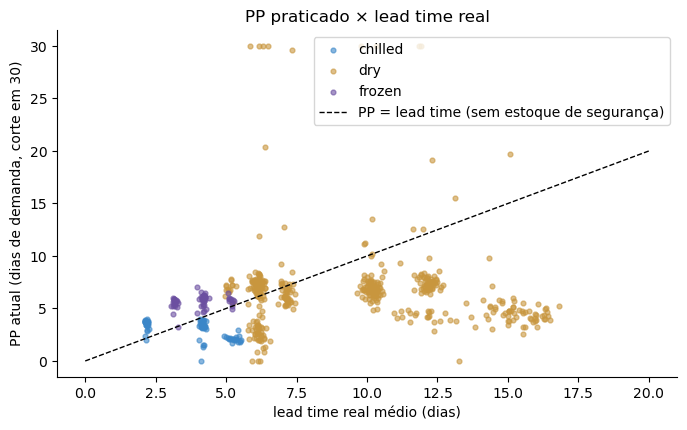

In [4]:
# Dispersão: PP atual (dias) × lead time real — se a regra fosse correta, o PP acompanharia o lead time.
fig, ax = plt.subplots(figsize=(8, 4.5))
for z, g in base.groupby("zone"):
    ax.scatter(g.lt_media, g.pp_atual_dias.clip(upper=30), s=12, alpha=0.6, label=z, color=ZONE_COLORS[z])
ax.plot([0, 20], [0, 20], color="black", ls="--", lw=1, label="PP = lead time (sem estoque de segurança)")
ax.set_xlabel("lead time real médio (dias)"); ax.set_ylabel("PP atual (dias de demanda, corte em 30)")
ax.set_title("PP praticado × lead time real"); ax.legend()
savefig(fig, "04d_pp_vs_leadtime")

print("Correlação PP(dias) × lead time real :", round(base.pp_atual_dias.corr(base.lt_media), 2))
print("Correlação PP(dias) × variabilidade (CV diário):",
      round(base.pp_atual_dias.corr(base.d_desvio / base.d_media), 2))

**Leitura:** o PP praticado é praticamente **um número fixo de dias por zona** (≈3,5 d resfriado,
≈6 d congelado, ≈7 d seco, com faixa interquartil estreita) e **não acompanha o lead time real**
(correlação ≈ 0,1). A correlação com a variabilidade (≈ 0,6) não é mérito da regra: vem da cauda de
SKUs de baixo giro, que têm CV alto e carregam muitos dias de estoque por causa de lote mínimo.
Na prática: SKUs cujo lead time real é maior que o PP **ficam sem estoque a cada reposição**.

In [5]:
# A regra explica a ruptura? Folga = PP atual (dias) − lead time real (dias)
base["folga_dias"] = base.pp_atual_dias - base.lt_media
faixas = pd.cut(base.folga_dias, [-np.inf, -3, -1, 0, 1, 3, np.inf],
                labels=["< −3", "−3 a −1", "−1 a 0", "0 a 1", "1 a 3", "> 3"])
folga = base.groupby(faixas, observed=True).agg(skus=("sku_id", "size"),
                                                corte_medio_pct=("corte_pct", "mean")).round(1)
folga

,skus,corte_medio_pct
folga_dias,,
< −3,255,15.0
−3 a −1,76,13.0
−1 a 0,54,3.8
0 a 1,59,5.0
1 a 3,139,2.4
> 3,16,9.2


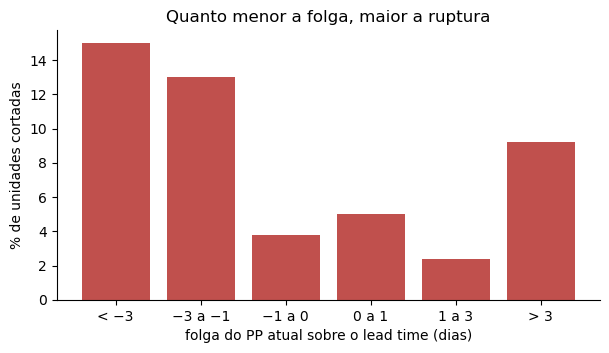

In [6]:
# Barras: compara a ruptura média entre faixas de folga (categorias ordenadas).
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(folga.index.astype(str), folga.corte_medio_pct, color="#C0504D")
ax.set_xlabel("folga do PP atual sobre o lead time (dias)"); ax.set_ylabel("% de unidades cortadas")
ax.set_title("Quanto menor a folga, maior a ruptura")
savefig(fig, "04d_ruptura_vs_folga")

## 3. Política proposta: ES e PP por SKU
Fórmula com incerteza de demanda **e** de lead time (lead time variável é o caso dos fornecedores
F007/F009/F011):

$$ES = z \cdot \sqrt{L \cdot \sigma_d^2 + \bar d^2 \cdot \sigma_L^2} \qquad PP = \bar d \cdot L + ES$$

- $\bar d$, $\sigma_d$: média e desvio da demanda diária · $L$, $\sigma_L$: média e desvio do lead time (dias)
- $z$ pelo nível de serviço da classe ABC (04c): **A = 98%**, **B = 95%**, **C = 90%**
- Premissa: demanda e lead time independentes e aproximadamente normais (estimativa; para itens Z
  o resultado é aproximado).

In [7]:
nivel = {"A": 0.98, "B": 0.95, "C": 0.90}
base["nivel_servico"] = base.abc.map(nivel)
base["z"] = base.nivel_servico.map(lambda p: NormalDist().inv_cdf(p))
base["es_und"] = base.z * np.sqrt(base.lt_media * base.d_desvio ** 2 +
                                  base.d_media ** 2 * base.lt_desvio.fillna(0) ** 2)
base["pp_proposto_und"] = base.d_media * base.lt_media + base.es_und
base["pp_proposto_dias"] = base.pp_proposto_und / base.d_media
# Estoque médio esperado na nova política = ES + metade do lote (lote atual mantido)
base["estoque_medio_proposto"] = base.es_und + base.lote_medio / 2
base["situacao"] = np.where(base.pp_atual_und < base.pp_proposto_und, "PP abaixo do necessário",
                            "PP acima do necessário")

comp = base.groupby(["zone", "situacao"]).agg(
    skus=("sku_id", "size"),
    pp_atual_dias=("pp_atual_dias", "median"), pp_proposto_dias=("pp_proposto_dias", "median"),
    corte_medio_pct=("corte_pct", "mean")).round(1)
comp

skus  pp_atual_dias  pp_proposto_dias  corte_medio_pct
zone    situacao                                                                       
chilled PP abaixo do necessário    90            3.4               6.9              7.1
dry     PP abaixo do necessário   439            6.6              15.6             11.2
        PP acima do necessário     10           48.7              24.4              8.2
frozen  PP abaixo do necessário    53            5.7               7.6              2.7
        PP acima do necessário      7            5.9               5.7              0.4

In [8]:
# Capital em estoque (a custo): atual × proposto
base["valor_atual"] = base.estoque_medio_atual * base.unit_cost
base["valor_proposto"] = base.estoque_medio_proposto * base.unit_cost
capital = base.groupby("zone")[["valor_atual", "valor_proposto"]].sum()
capital.loc["Total"] = capital.sum()
capital["variacao_pct"] = (100 * (capital.valor_proposto / capital.valor_atual - 1)).round(1)
capital.round(0)

,valor_atual,valor_proposto,variacao_pct
zone,,,
chilled,703570.0,926875.0,32.0
dry,3060460.0,2942989.0,-4.0
frozen,480177.0,446394.0,-7.0
Total,4244208.0,4316257.0,2.0


**Leitura:**
- A ruptura cai de forma nítida conforme a folga do PP sobre o lead time aumenta: **15% de corte**
  quando o PP fica 3+ dias abaixo do lead time × **2–5%** quando há folga. É a causa principal do
  In Full baixo do B2B.
- Quase todos os SKUs (≈580 de 599) estão com PP **abaixo** do necessário: a regra atual cobre
  no máximo o lead time médio, sem margem para variabilidade de demanda e de entrega. No seco, a
  mediana precisaria ir de ≈7 para ≈16 dias de cobertura (fornecedores lentos/variáveis pesam).
- **Capital em estoque (estimativa): +2% no total** — o frio sobe (+32%, onde a regra atual é mais
  apertada), mas é compensado pela redução no seco e no congelado, onde poucos SKUs carregam
  estoque demais (PP de ~49 dias; ver estoque parado em 04e).
- Ou seja: **mais nível de serviço quase sem aumento de capital**, redistribuindo estoque dos itens
  parados para os de giro. *Estimativa:* validar por simulação (Fase 6) ou piloto na curva A.

In [9]:
saida = base[["sku_id", "sku_code", "zone", "supplier_id", "abc", "xyz", "classe", "d_media",
              "d_desvio", "lt_media", "lt_desvio", "lote_medio", "pp_atual_und", "pp_atual_dias",
              "nivel_servico", "es_und", "pp_proposto_und", "pp_proposto_dias", "estoque_medio_atual",
              "estoque_medio_proposto", "corte_pct", "situacao"]].round(2)
save(saida, "sku_safety_stock_rop")

WindowsPath('C:/Users/johnw/Desktop/Projetos/simulação CD/reports/phase4/sku_safety_stock_rop.csv')

## 4. Previsão de demanda semanal por zona
Para capacidade (docas, separação, câmaras) e compras, prever o **agregado** é mais útil e mais
preciso que prever SKU a SKU.

**Escolha do método:** Holt-Winters com sazonalidade anual precisa de **pelo menos 2 ciclos
completos (104 semanas) só para treinar** — temos 103 semanas no total, então não há como
treiná-lo e ainda reservar um período de teste. Usamos três métodos simples e explicáveis:
1. **Ingênuo sazonal:** previsão = mesma semana do ano anterior.
2. **Ingênuo sazonal ajustado pelo nível:** mesma semana do ano anterior × (últimas 8 semanas /
   as mesmas 8 semanas do ano anterior). Corrige crescimento ou queda do volume.
3. **Holt (tendência, sem sazonalidade):** referência para mostrar o custo de ignorar a sazonalidade.

**Backtest:** previsão das últimas 26 semanas usando só o que se sabia antes delas.
Métrica: WAPE = soma |erro| / soma do real.

In [10]:
sem = q("""SELECT s.zone, f.order_date, SUM(f.qty_ordered_units) AS und
           FROM fact_order_line f JOIN dim_sku s ON s.sku_id = f.sku_id
           WHERE f.order_date BETWEEN :i AND :f GROUP BY 1, 2""", i=INI, f=FIM)
sem["semana"] = pd.to_datetime(sem.order_date).dt.to_period("W-SUN")
sem = sem.pivot_table(index="semana", columns="zone", values="und", aggfunc="sum").iloc[1:-1]
H = 26          # semanas de teste
JANELA = 8      # semanas usadas para medir o nível recente

def wape(real, prev):
    """Erro percentual absoluto ponderado pelo volume."""
    return 100 * np.abs(np.asarray(real) - np.asarray(prev)).sum() / np.asarray(real).sum()

def sazonal_ajustado(serie, h):
    """Mesma semana do ano anterior x fator de nível (últimas 8 semanas vs. 52 semanas antes)."""
    fator = serie.iloc[-JANELA:].sum() / serie.iloc[-JANELA - 52:-52].sum()
    return serie.iloc[-52:-52 + h].values * fator if h < 52 else None

resultados, previsoes = [], {}
for z in sem.columns:
    treino, real = sem[z].iloc[:-H], sem[z].iloc[-H:]
    p_ingenuo = sem[z].shift(52).iloc[-H:].values
    p_ajustado = sazonal_ajustado(treino, H)
    p_holt = ExponentialSmoothing(treino.values, trend="add",
                                  initialization_method="estimated").fit().forecast(H)
    previsoes[z] = p_ajustado
    resultados.append({"zona": z,
                       "WAPE_ingenuo_sazonal": round(wape(real, p_ingenuo), 1),
                       "WAPE_sazonal_ajustado": round(wape(real, p_ajustado), 1),
                       "WAPE_holt_sem_sazonalidade": round(wape(real, p_holt), 1)})
backtest = pd.DataFrame(resultados)
save(backtest, "04d_forecast_backtest")
backtest

,zona,WAPE_ingenuo_sazonal,WAPE_sazonal_ajustado,WAPE_holt_sem_sazonalidade
0,chilled,4.2,3.9,21.9
1,dry,4.9,3.3,13.1
2,frozen,6.8,3.9,17.0


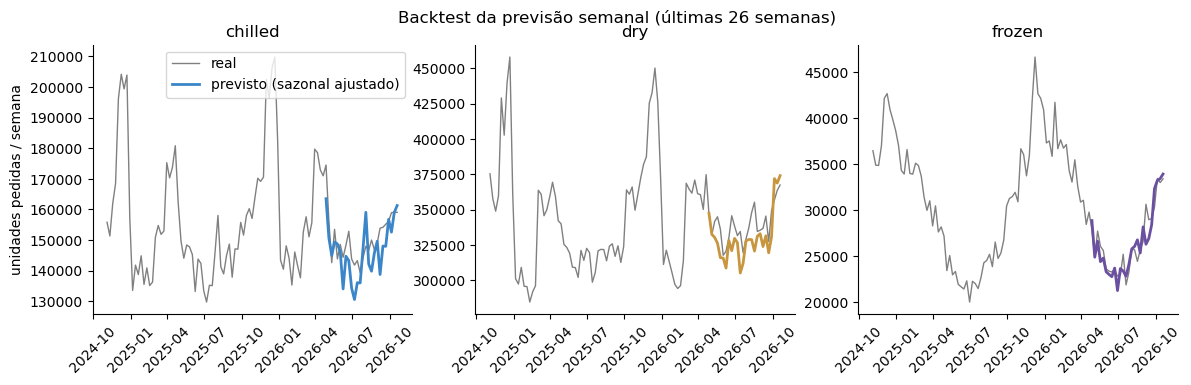

In [11]:
# Linha: real × previsto no período de teste (avaliação visual do backtest).
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, z in zip(axes, sem.columns):
    ax.plot(sem.index.to_timestamp(), sem[z], color="grey", lw=1, label="real")
    ax.plot(sem.index[-H:].to_timestamp(), previsoes[z], color=ZONE_COLORS[z], lw=2,
            label="previsto (sazonal ajustado)")
    ax.set_title(z); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("unidades pedidas / semana"); axes[0].legend()
fig.suptitle("Backtest da previsão semanal (últimas 26 semanas)")
savefig(fig, "04d_forecast_backtest")

In [12]:
# Previsão para as próximas 13 semanas (nov/2026 a jan/2027), com todo o histórico
idx = pd.period_range(sem.index[-1] + 1, periods=13, freq="W-SUN")
futuro = pd.DataFrame({z: sazonal_ajustado(sem[z], 13) for z in sem.columns}, index=idx).round(0)
# A mesma janela um ano antes (as 13 semanas seguintes à semana equivalente de 2025)
ano_anterior = sem.iloc[-52:-52 + 13]
print("Volume previsto nas próximas 13 semanas vs. mesmas semanas do ano anterior (%):")
print((100 * (futuro.sum() / ano_anterior.sum() - 1)).round(1))
save(futuro.reset_index().astype({"index": str}).rename(columns={"index": "semana"}),
     "04d_forecast_next13w")
futuro.T

Volume previsto nas próximas 13 semanas vs. mesmas semanas do ano anterior (%):
chilled    3.2
dry        3.3
frozen     7.4
dtype: float64


,2026-10-26/2026-11-01,2026-11-02/2026-11-08,2026-11-09/2026-11-15,2026-11-16/2026-11-22,2026-11-23/2026-11-29,2026-11-30/2026-12-06,2026-12-07/2026-12-13,2026-12-14/2026-12-20,2026-12-21/2026-12-27,2026-12-28/2027-01-03,2027-01-04/2027-01-10,2027-01-11/2027-01-17,2027-01-18/2027-01-24
chilled,162133.0,169135.0,175687.0,174635.0,176065.0,209014.0,202585.0,212719.0,216532.0,187862.0,148112.0,145038.0,152907.0
dry,360961.0,372610.0,384565.0,394477.0,400051.0,439134.0,446904.0,464846.0,439917.0,384029.0,321278.0,331691.0,323506.0
frozen,33177.0,39369.0,38678.0,36207.0,38545.0,44946.0,50082.0,45805.0,45250.0,43938.0,40047.0,40281.0,38481.0


**Leitura:** o método sazonal ajustado é o recomendado para planejar o pico de fim de ano: simples,
explicável e com erro baixo no backtest. Ignorar a sazonalidade (Holt) piora o erro. Com um terceiro
ano de histórico, vale testar Holt-Winters/ETS completos. A previsão do pico 2026/27 alimenta a
simulação de capacidade da Fase 6 — lembrando que em dez/2025 a separação já não deu conta (04b).

In [13]:
log(NB, f"política atual inferida (estoque no dia do PO / demanda média); ES/PP por SKU "
        f"(z por ABC: A 98%, B 95%, C 90%) para {len(saida)} SKUs -> sku_safety_stock_rop.csv; "
        f"previsão semanal por zona (sazonal ajustado), backtest {H} semanas")